### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [95]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [96]:
data = pd.read_csv('data/coupons.csv')

In [97]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [99]:
# Investigate missing or problematic values in the dataset
print("Dataset shape:", data.shape)

missing = data.isna().sum()
print("\nMissing values by column:")
print(missing[missing > 0])

print(f"\nRows with any missing values: {data.isna().any(axis=1).sum()}")



Dataset shape: (12684, 26)

Missing values by column:
car                     12576
Bar                       107
CoffeeHouse               217
CarryAway                 151
RestaurantLessThan20      130
Restaurant20To50          189
dtype: int64

Rows with any missing values: 12576


3. Decide what to do about your missing data -- drop, replace, other...

In [64]:
# Keep rows intact, remove the mostly-missing car column, and label missing categorical values.
missing_counts = data.isna().sum()
print("Missing values by column:")
print(missing_counts[missing_counts > 0])

# remove the 'car' column
data = data.drop(columns=["car"], errors="ignore")

# Fill missing values in categorical columns with "Unknown"
categorical_columns = [
    "Bar",
    "CoffeeHouse",
    "CarryAway",
    "RestaurantLessThan20",
    "Restaurant20To50",
]
data[categorical_columns] = data[categorical_columns].fillna("Unknown")

# Remaining missing values count
print("\nRemaining missing values:", data.isna().sum().sum())

# Display the cleaned and preprocessed data
print("\nData after cleaning and preprocessing:")
print(data.head())   

Missing values by column:
car                     12576
Bar                       107
CoffeeHouse               217
CarryAway                 151
RestaurantLessThan20      130
Restaurant20To50          189
dtype: int64

Remaining missing values: 0

Data after cleaning and preprocessing:
       destination  passanger weather  temperature  time  \
0  No Urgent Place      Alone   Sunny           55   2PM   
1  No Urgent Place  Friend(s)   Sunny           80  10AM   
2  No Urgent Place  Friend(s)   Sunny           80  10AM   
3  No Urgent Place  Friend(s)   Sunny           80   2PM   
4  No Urgent Place  Friend(s)   Sunny           80   2PM   

                  coupon expiration  gender age      maritalStatus  ...  \
0        Restaurant(<20)         1d  Female  21  Unmarried partner  ...   
1           Coffee House         2h  Female  21  Unmarried partner  ...   
2  Carry out & Take away         2h  Female  21  Unmarried partner  ...   
3           Coffee House         2h  Female  21  Un

4. What proportion of the total observations chose to accept the coupon?



In [100]:
# Analyze the proportion of accepted coupons
Data_Coupons_Accepted = data[data['Y'] == 1].copy()
proportion_accepted = len(Data_Coupons_Accepted) / len(data)

# print the results
print(f"Number of accepted coupons: {len(Data_Coupons_Accepted)}")
print(f"Proportion of accepted coupons: {proportion_accepted:.2%}")

Number of accepted coupons: 7210
Proportion of accepted coupons: 56.84%


5. Use a bar plot to visualize the `coupon` column.

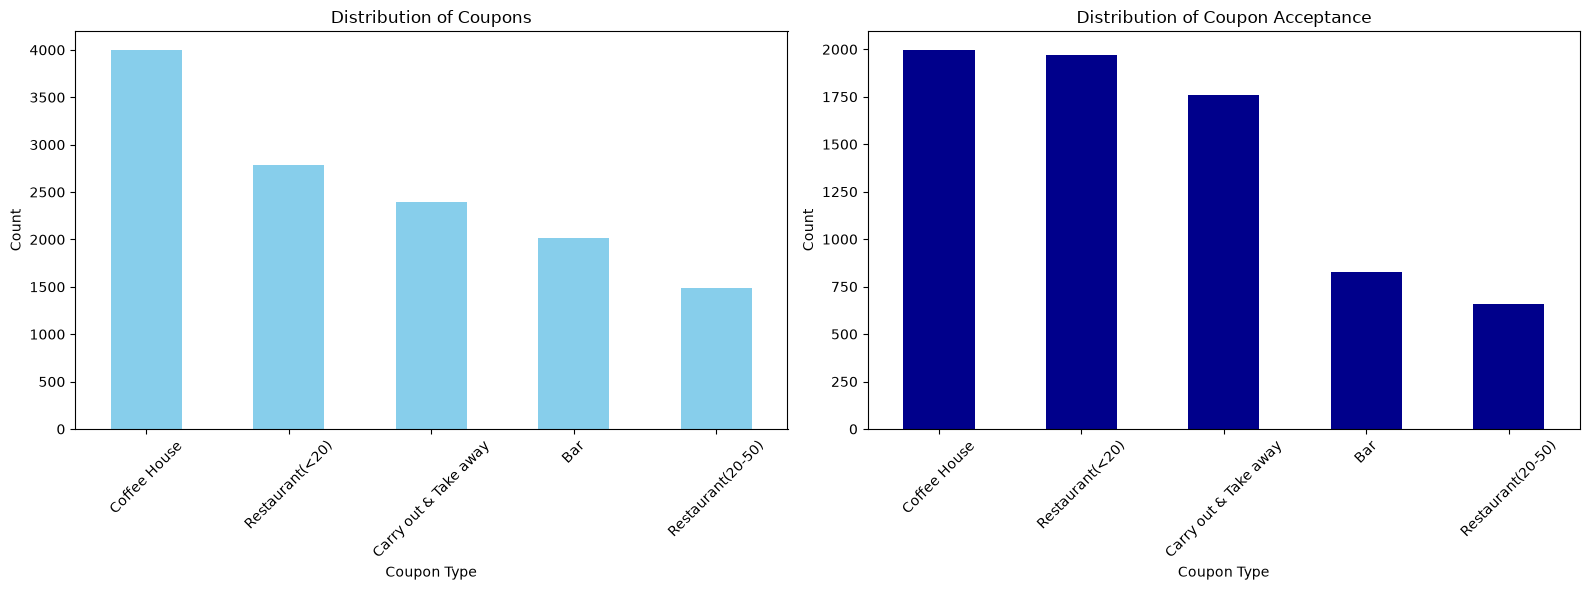

In [113]:
# Visualize the distribution of coupons using a bar plot and the distribution of coupon acceptance using a bar plot on coupons that were accepted
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# Plot both charts side by side
# Visualize the distribution of coupons using a bar plot
data['coupon'].value_counts().plot(ax=axes[0], kind='bar', color='skyblue')
axes[0].set_xlabel('Coupon Type')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Coupons')
axes[0].tick_params(axis='x', rotation=45)

# Visualize the distribution of coupon acceptance using a bar plot on coupons that were accepted
Data_Coupons_Accepted['coupon'].value_counts().plot(ax=axes[1], kind='bar', color='darkblue')
axes[1].set_xlabel('Coupon Type')
axes[1].set_ylabel('Count')
axes[1].set_title('Distribution of Coupon Acceptance')
axes[1].tick_params(axis='x', rotation=45)

fig.tight_layout()


6. Use a histogram to visualize the temperature column.

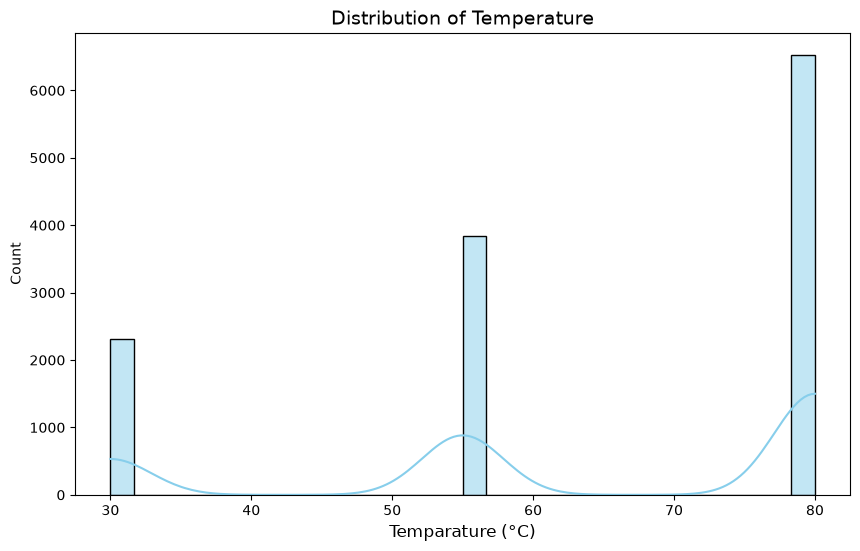

In [147]:
plt.figure(figsize=(10, 6))

sns.histplot(data=data, x="temperature", kde=True, bins=30, color="skyblue")

plt.title("Distribution of Temperature", fontsize=14)
plt.xlabel("Temparature (°C)", fontsize=12)
plt.ylabel("Count")
plt.show()

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [115]:
# Create a new DataFrame for drivers who received Bar coupons
Data_Bar_Coupons = data[data['coupon'] == 'Bar'].copy()
print(Data_Bar_Coupons.head()) # to print the entire DataFrame, you can use print(Data_Bar_Coupons.to_string()) instead of print(Data_Bar_Coupons.head())

        destination  passanger weather  temperature  time coupon expiration  \
9   No Urgent Place     Kid(s)   Sunny           80  10AM    Bar         1d   
13             Home      Alone   Sunny           55   6PM    Bar         1d   
17             Work      Alone   Sunny           55   7AM    Bar         1d   
24  No Urgent Place  Friend(s)   Sunny           80  10AM    Bar         1d   
35             Home      Alone   Sunny           55   6PM    Bar         1d   

    gender age      maritalStatus  ...  CoffeeHouse CarryAway  \
9   Female  21  Unmarried partner  ...        never       NaN   
13  Female  21  Unmarried partner  ...        never       NaN   
17  Female  21  Unmarried partner  ...        never       NaN   
24    Male  21             Single  ...        less1       4~8   
35    Male  21             Single  ...        less1       4~8   

   RestaurantLessThan20 Restaurant20To50 toCoupon_GEQ5min toCoupon_GEQ15min  \
9                   4~8              1~3               

2. What proportion of bar coupons were accepted?


In [148]:
# Calculate the proportion of accepted Bar coupons
Data_Bar_Coupons_Accepted = Data_Bar_Coupons[Data_Bar_Coupons['Y'] == 1].copy()
Total_Bar_Coupons = len(Data_Bar_Coupons)
p_acc_bar_cpns = len(Data_Bar_Coupons_Accepted) / Total_Bar_Coupons
print(f"Number of accepted Bar coupons: {len(Data_Bar_Coupons_Accepted)}")
print(f"Number of all Bar coupons: {Total_Bar_Coupons}")
print(f"Proportion of accepted Bar coupons: {p_acc_bar_cpns:.2%}")

# Calculate the Proportion of accepted Bar coupons using mean and comparing it with the previous calculation
acc_bar_rate = Data_Bar_Coupons["Y"].mean()
print(f"Proportion of accepted Bar coupons using mean: {acc_bar_rate:.2%}")

Number of accepted Bar coupons: 827
Number of all Bar coupons: 2017
Proportion of accepted Bar coupons: 41.00%
Proportion of accepted Bar coupons using mean: 41.00%


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [149]:
# Compare all bar coupon offers by how often the driver goes to a bar
# 3 or fewer times 
bar_goer_lte3 = Data_Bar_Coupons[
	Data_Bar_Coupons["Bar"].isin(["never", "less1", "1~3"])
]["Y"].mean()

# more than 3 times
bar_goer_gt3 = Data_Bar_Coupons[
	Data_Bar_Coupons["Bar"].isin(["4~8", "gt8"])
]["Y"].mean()

# print the results
print(f"Acceptance rate of bar goers (3 or fewer times): {bar_goer_lte3:.2%}")
print(f"Acceptance rate of bar goers (more than 3 times): {bar_goer_gt3:.2%}")
print(f"Difference in acceptance rate: {bar_goer_lte3 - bar_goer_gt3:.2%}")

Acceptance rate of bar goers (3 or fewer times): 37.06%
Acceptance rate of bar goers (more than 3 times): 76.88%
Difference in acceptance rate: -39.82%


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [139]:
# convert age to numeric for comparison
age_numeric = pd.to_numeric(
    Data_Bar_Coupons["age"].replace({"below21": 20, "50plus": 50}),
    errors="coerce"
)

# Drivers over 25 who go to bars more than 1x/month
driver_bar_gt1 = Data_Bar_Coupons[
    (Data_Bar_Coupons["Bar"].isin(["1~3", "4~8", "gt8"])) &
    (age_numeric > 25)
].copy()

# Calculate the acceptance rate for drivers others who go to bars more than 1x/month
driver_bar_other = Data_Bar_Coupons[
    ~(
        (Data_Bar_Coupons["Bar"].isin(["1~3", "4~8", "gt8"])) &
        (age_numeric <= 25)
    )
].copy()

print(f"Drivers over 25 who go to bars > 1x/month: {len(driver_bar_gt1)}")
print(f"Acceptance rate in this group: {driver_bar_gt1['Y'].mean():.2%}")
print(f"Drivers in other groups: {len(driver_bar_other)}")
print(f"Acceptance rate in all other bar drivers: {driver_bar_other['Y'].mean():.2%}")
print(f"Difference: {driver_bar_gt1['Y'].mean() - driver_bar_other['Y'].mean():.2%}")



Drivers over 25 who go to bars > 1x/month: 420
Acceptance rate in this group: 69.52%
Drivers in other groups: 1841
Acceptance rate in all other bar drivers: 38.51%
Difference: 31.01%


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [159]:
# Find drivers who go to bars more than once a month, are not traveling with kids, and are not in farming, fishing or forestry occupations
bar_gt1 = Data_Bar_Coupons["Bar"].isin(["1~3", "4~8", "gt8"])
pass_not_kid = Data_Bar_Coupons["passanger"] != "Kid(s)"
occ_not_farm = ~Data_Bar_Coupons["occupation"].str.contains(
    "farming", case=False, na=False
)
occ_not_fish = ~Data_Bar_Coupons["occupation"].str.contains(
    "fishing", case=False, na=False
)
occ_not_forest = ~Data_Bar_Coupons["occupation"].str.contains(
    "forestry", case=False, na=False
)

qual_drivers = bar_gt1 & pass_not_kid & occ_not_farm & occ_not_fish & occ_not_forest

driver_bar_gt1 = Data_Bar_Coupons[
    qual_drivers
].copy()

driver_bar_other = Data_Bar_Coupons[~qual_drivers].copy()

group_rate = driver_bar_gt1["Y"].mean()
other_rate = driver_bar_other["Y"].mean()

print(f"qual drivers who go to bars more than once a month: {len(driver_bar_gt1)}")
print(f"acc rate in this group: {group_rate:.2%}")
print(f"Other bar drivers: {len(driver_bar_other)}")
print(f"acc rate in all other bar drivers: {other_rate:.2%}")
print(f"diff: {group_rate - other_rate:.2%}")


qual drivers who go to bars more than once a month: 551
acc rate in this group: 71.32%
Other bar drivers: 1466
acc rate in all other bar drivers: 29.60%
diff: 41.72%


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [154]:
# Find drivers who go to bars more than once a month, are not traveling with kids, and are not widowed
bar_gt1 = Data_Bar_Coupons["Bar"].isin(["1~3", "4~8", "gt8"])
pass_not_kid = Data_Bar_Coupons["passanger"] != "Kid(s)"
not_widowed = Data_Bar_Coupons["maritalStatus"] != "Widowed"

# Age under 30
Age_under_30 = Data_Bar_Coupons["age"].isin(["below21", "26-35"])
driver_1m_nokid_notwidd = bar_gt1 & pass_not_kid & not_widowed

Data_driver_1m_nokid_notwid = Data_Bar_Coupons[
    driver_1m_nokid_notwidd
].copy()

driver_1m_u30 = bar_gt1 & Age_under_30

Data_driver_1m_u30 = Data_Bar_Coupons[
    driver_1m_u30
].copy()

# Drivers who go to cheap restaurants more than 4 times a month
# and have an income below $50k
cheap_restaurants_more_than_4 = Data_Bar_Coupons["RestaurantLessThan20"].isin(["4~8", "gt8"])
income_under_50k = Data_Bar_Coupons["income"].str.lower().isin([
    "less than $12500",
    "$12500 - $24999",
    "$25000 - $37499",
    "$37500 - $49999"
])
qualifying_drivers3 = cheap_restaurants_more_than_4 & income_under_50k

driver_1m_cheap_u50k = Data_Bar_Coupons[
    qualifying_drivers3
].copy()

# calculate the acceptance rates for each group and the difference from the other bar drivers
other_bar_drivers = Data_Bar_Coupons[
    ~(driver_1m_nokid_notwidd | driver_1m_u30 | qualifying_drivers3)
].copy()

group_rate1 = Data_driver_1m_nokid_notwid["Y"].mean()
group_rate2 = Data_driver_1m_u30["Y"].mean()
group_rate3 = driver_1m_cheap_u50k["Y"].mean()
other_rate = other_bar_drivers["Y"].mean()

# print the results
print(f"qual driver_1m_nokid_notwid: {len(Data_driver_1m_nokid_notwid)}")
print(f"qual driver_1m_u30: {len(Data_driver_1m_u30)}")
print(f"qual driver_1m_cheap_u50k: {len(driver_1m_cheap_u50k)}")
print(f"qual other_bar_drivers: {len(other_bar_drivers)}")
print(f"acc rate in driver_1m_nokid_notwid group: {group_rate1:.2%}")
print(f"acc rate in driver_1m_u30 group: {group_rate2:.2%}")
print(f"acc rate in driver_1m_cheap_u50k group: {group_rate3:.2%}")
print(f"acc rate in other_bar_drivers group: {other_rate:.2%}")
print(f"diff between driver_1m_nokid_notwid and other_bar_drivers: {group_rate1 - other_rate:.2%}")
print(f"diff between driver_1m_u30 and other_bar_drivers: {group_rate2 - other_rate:.2%}")
print(f"diff between driver_1m_cheap_u50k and other_bar_drivers: {group_rate3 - other_rate:.2%}")


qual driver_1m_nokid_notwid: 551
qual driver_1m_u30: 10
qual driver_1m_cheap_u50k: 344
qual other_bar_drivers: 1245
acc rate in driver_1m_nokid_notwid group: 71.32%
acc rate in driver_1m_u30 group: 40.00%
acc rate in driver_1m_cheap_u50k group: 45.35%
acc rate in other_bar_drivers group: 29.96%
diff between driver_1m_nokid_notwid and other_bar_drivers: 41.37%
diff between driver_1m_u30 and other_bar_drivers: 10.04%
diff between driver_1m_cheap_u50k and other_bar_drivers: 15.39%


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

In [146]:
"The drivers who go to bars more than once a month, have passengers other than kids, and are not widowed have the highest acceptance rate of bar coupons."

'The drivers who go to bars more than once a month, have passengers other than kids, and are not widowed have the highest acceptance rate of bar coupons.'

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

Bar coupon acceptance by education level:
                                        count  acceptance_rate
education                                                     
Some High School                           14         0.785714
Some college - no degree                  708         0.449153
Bachelors degree                          684         0.410819
High School Graduate                      148         0.391892
Graduate degree (Masters or Doctorate)    271         0.376384
Associates degree                         192         0.296875


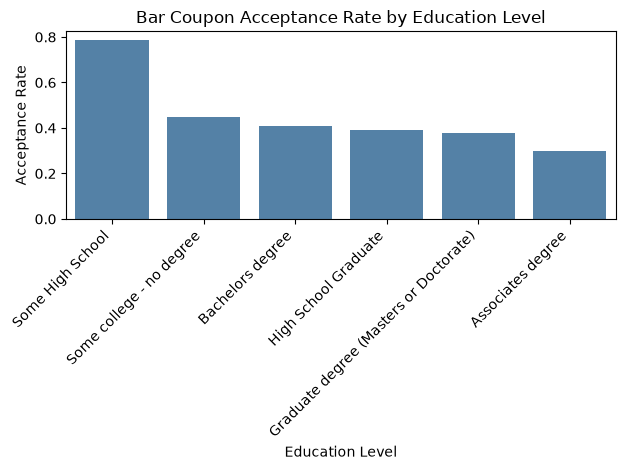

In [92]:
# Education-based analysis of bar coupon acceptance
analysis = (
    Data_Bar_Coupons.groupby("education")
    .agg(count=("Y", "size"), acceptance_rate=("Y", "mean"))
    .sort_values("acceptance_rate", ascending=False)
)

print("Bar coupon acceptance by education level:")
print(analysis)

sns.barplot(
    data=analysis.reset_index(),
    x="education",
    y="acceptance_rate",
    color="steelblue"
)
plt.title("Bar Coupon Acceptance Rate by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Acceptance Rate")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

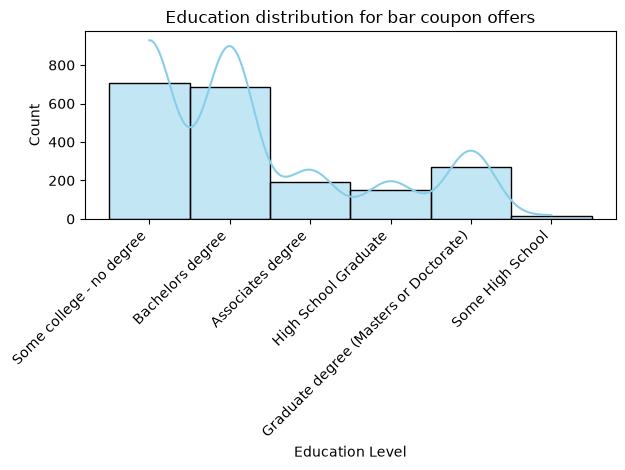

In [94]:
histo = sns.histplot(
    data=Data_Bar_Coupons,
    x="education",
    bins=20,
    kde=True,
    color="skyblue"
)

plt.title("Education distribution for bar coupon offers")
plt.xlabel("Education Level")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [160]:
education_acceptance = Data_Bar_Coupons.groupby("education")["Y"].mean().sort_values(ascending=False)
print("\nAcceptance rate by education level:")
print(education_acceptance)





Acceptance rate by education level:
education
Some High School                          0.785714
Some college - no degree                  0.449153
Bachelors degree                          0.410819
High School Graduate                      0.391892
Graduate degree (Masters or Doctorate)    0.376384
Associates degree                         0.296875
Name: Y, dtype: float64


In [86]:
education_distribution = Data_Bar_Coupons["education"].value_counts(normalize=True).sort_index()
print("\nProportion of each education level in the bar coupon dataset:")
print(education_distribution)


Proportion of each education level in the bar coupon dataset:
education
Associates degree                         0.095191
Bachelors degree                          0.339118
Graduate degree (Masters or Doctorate)    0.134358
High School Graduate                      0.073376
Some High School                          0.006941
Some college - no degree                  0.351016
Name: proportion, dtype: float64


In [88]:
percentage = education_distribution * 100
print("\nPercentage of each education level in the bar coupon dataset:")
print(percentage.map("{:.2f}%".format))


Percentage of each education level in the bar coupon dataset:
education
Associates degree                          9.52%
Bachelors degree                          33.91%
Graduate degree (Masters or Doctorate)    13.44%
High School Graduate                       7.34%
Some High School                           0.69%
Some college - no degree                  35.10%
Name: proportion, dtype: str


Y,0,1
coupon,,
Bar,1190,827
Carry out & Take away,633,1760
Coffee House,2001,1995
Restaurant(20-50),834,658
Restaurant(<20),816,1970


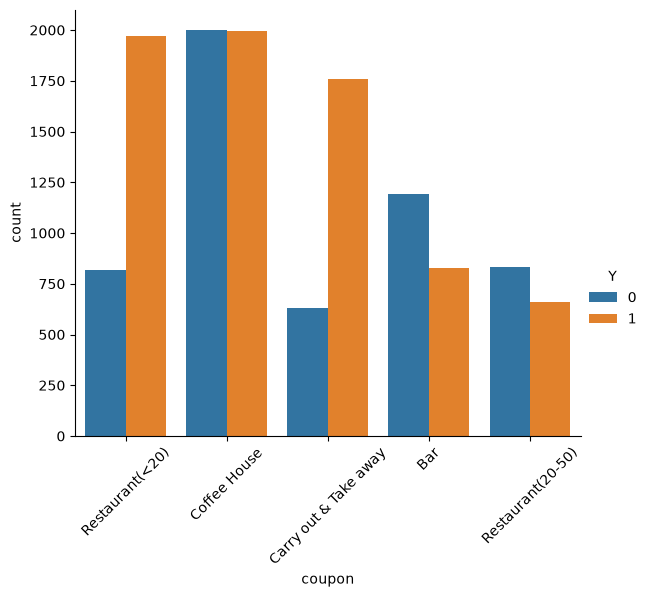

In [163]:
# catplot to visualize the distribution of coupon acceptance by Type of coupon and acceptance status
g = sns.catplot(
    data=data,
    x='coupon',
    hue='Y',
    kind='count',
    height=5,
    aspect=1.2
)
# Display number of accepted coupons by type of coupon and acceptance status in cross tabulation format
display(data.groupby(['coupon', 'Y']).size().unstack(fill_value=0))

# Rotate labels on all subplots seamlessly
g.set_xticklabels(rotation=45)
# Print the visualization
plt.show()